# Урок 5. Несколько пятен: цвет, непрозрачность и перекрытия

[План и запуск](../../README_ru.md) · [Предыдущий урок](lesson-04.ipynb) · [English](../en/lesson-05.ipynb)

Одно пятно мы уже умеем двигать, растягивать и поворачивать. Давай положим рядом второе. Там, где они перекроются, программе придётся выбрать цвет. Просто сложить красный и синий? Взять среднее? А если одно пятно почти прозрачное?

Начнём с двух пятен на белом фоне и поменяем их местами в списке. Картинка изменится, хотя ни координаты, ни размеры, ни цвета мы не трогали. Разберём, откуда берётся эта разница, и вручную посчитаем один пиксель.

В конце соберём небольшой редактор: можно добавлять пятна, менять их форму, цвет, непрозрачность и порядок. Сцену сохраним в JSON, чтобы потом вернуться к ней. Пока все параметры подбираем руками; в следующем блоке начнём поручать эту работу программе.

## 1. Поменяем местами два пятна

Запусти ячейки по порядку. На первой картинке красное пятно находится перед синим. На второй — наоборот. Справа показана разница: чёрный означает совпадение, светлые участки — различие. На GitHub эти картинки уже видны; ползунки редактора работают в Jupyter.

Слова «спереди» и «сзади» пока означают **порядок в списке**, который мы задаём сами. Здесь нет трёхмерной камеры и расчёта глубины. Первый элемент списка — передний слой.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
from IPython.display import display

course_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "mixing_demos.py").is_file()), None
)
if course_root is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from gaussian_math import composite_at, load_scene_json
from mixing_demos import (
    overlap_figure, alpha_figure, pixel_figure, editor_figure,
    preset_scene, gaussian_editor,
)
LANG = 'ru'

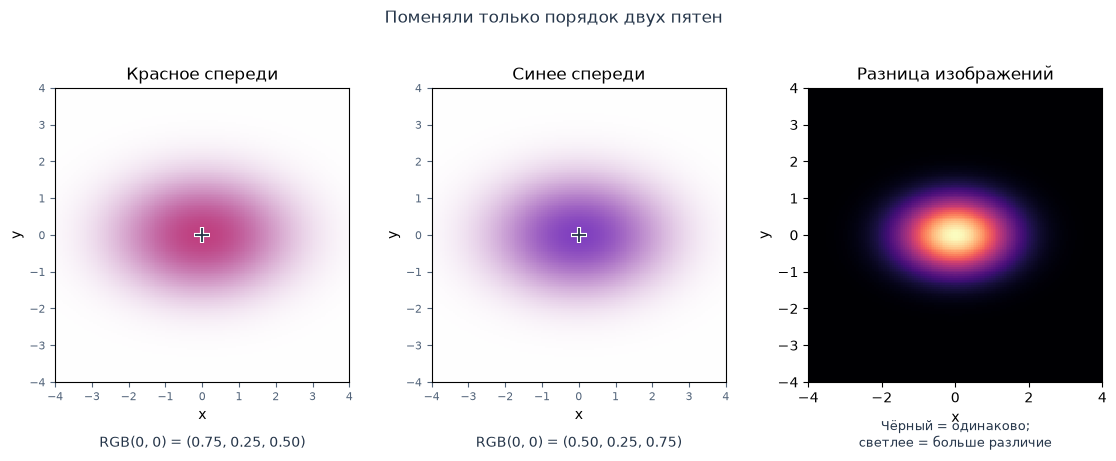

In [2]:
display(overlap_figure(language=LANG))
editor = gaussian_editor(language=LANG)
display(editor)

В редакторе сначала нажми **«Сбросить всё»**. Получатся два пятна с общим центром `(0, 0)`, масштабами `1.5` и `1`, без поворота. Непрозрачность каждого — `0.5`, фон белый. Крестик тоже стоит в центре.

Попробуй четыре вещи:

1. Выбери красное пятно и нажми **«На слой дальше»**. Числа в его карточке сохранились, но цвет в центре поменялся. Верни его кнопкой **«На слой ближе»**.
2. Уменьши непрозрачность красного до нуля. Его цвет исчезнет. Пунктирный контур останется, пока включён показ выбранного пятна: это подсказка редактора, а не часть картинки.
3. Верни непрозрачность `0.5` и сдвинь красное по горизонтали. Теперь в разных пикселях у него разная сила влияния. Следи за таблицей под изображением.
4. Нажми **«Сбросить всё»**, затем сдвинь только **«Пиксель x»**. Крестик и расчёт переместятся, а пятна останутся на месте.

Цветную картинку мы уже получили. Теперь разберём числа, из которых она сложилась.

## 2. Цвет — три числа

Для цвета возьмём три канала: **R** — красный, **G** — зелёный, **B** — синий. В каждом канале храним число от 0 до 1. Тройку удобно записать так:

$$
c=(r,g,b).
$$

$c$ — весь цвет; $r,g,b$ — три его составляющие в указанном порядке. Скобки объединяют числа в одну запись. Это безразмерные значения, а не координаты точки. Буква $G$ у гауссианы дальше будет обозначать вес; зелёный **канал** в формулах обозначим маленькой $g$.

| Цвет | RGB | Как прочитать |
|---|---|---|
| Красный | `(1, 0, 0)` | Красный канал включён полностью, остальные равны нулю |
| Синий | `(0, 0, 1)` | Полностью включён синий канал |
| Белый | `(1, 1, 1)` | Все три канала равны 1 |
| Чёрный | `(0, 0, 0)` | Все три канала равны 0 |
| Серый | `(0.5, 0.5, 0.5)` | Все каналы имеют одинаковое промежуточное значение |

Умножить цвет на число — значит умножить **каждый канал**:

$$
0.5(1,0,0)=(0.5\cdot1,\;0.5\cdot0,\;0.5\cdot0)=(0.5,0,0).
$$

Сложение тоже идёт по каналам. Например, $(0.5,0,0)+(0,0,0.25)=(0.5,0,0.25)$. Красное число прибавляем к красному, зелёное — к зелёному, синее — к синему.

В этом редакторе смешиваем числовые RGB как записаны и показываем результат без отдельной гамма-коррекции. Это удобный учебный расчёт перекрытий. Он не моделирует физическое смешивание света; при работе с реальными изображениями отдельно учитывают, как закодирован цвет.

## 3. Вес пятна и непрозрачность — два разных числа

В прошлых уроках мы вычисляли $G(x,y)$: вес гауссианы в точке с координатами $x,y$. В центре он равен 1, дальше уменьшается. За форму отвечают центр, масштабы и поворот.

Теперь добавим **непрозрачность** $o$ — одно число для всей гауссианы от 0 до 1. Здесь $o$ — маленькая латинская буква «о», не ноль. Она позволяет ослабить пятно целиком, не двигая и не растягивая его.

Чтобы узнать силу цветового вклада в конкретном месте, перемножим эти два числа:

$$
\alpha(x,y)=o\,G(x,y).
$$

Греческую $\alpha$ читаем «альфа». Запись $o\,G$ означает обычное умножение. Сначала считаем пространственный вес, затем умножаем на непрозрачность. Полученная альфа тоже лежит между 0 и 1 и не имеет единиц измерения.

При $o=0.5$:

- в центре: $G(0,0)=1$, поэтому $\alpha(0,0)=0.5\cdot1=0.5$;
- на одной ширине вдоль оси: $G\approx0.606531$, поэтому $\alpha=0.5\exp(-0.5)\approx0.303265$;
- далеко от центра маленький $G$ даёт ещё меньшую альфу.

Не нужно отдельно запоминать каждую альфу картинки. В данных храним одну непрозрачность, а альфу пересчитываем для каждого пикселя. На следующем рисунке синяя линия — вес, оранжевая — вес после умножения на `0.5`.

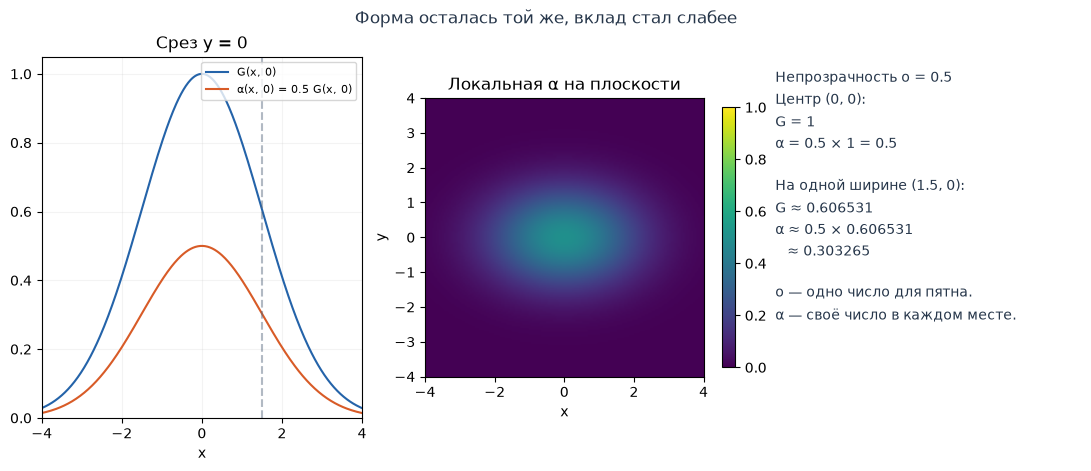

In [3]:
display(alpha_figure(language=LANG))

## 4. Одно пятно поверх фона

Пусть в выбранном пикселе альфа равна `0.5`. Тогда половину вклада отдаём цвету пятна, а вторую половину — тому, что находится сзади. Остаток считаем вычитанием: $1-0.5=0.5$.

Для одного пятна на непрозрачном фоне:

$$
C=\alpha c+(1-\alpha)B.
$$

Здесь $C$ — получившийся RGB пикселя, $c$ — цвет пятна, $B$ — цвет фона. Все три величины — тройки чисел. Альфа и $1-\alpha$ — обычные числа, которыми умножаем каждую тройку. Фон у нас непрозрачный: за ним ничего не просвечивает.

Возьмём красный $c=(1,0,0)$ и белый фон $B=(1,1,1)$:

$$
\begin{aligned}
C&=0.5(1,0,0)+(1-0.5)(1,1,1)\\
&=(0.5,0,0)+0.5(1,1,1)\\
&=(0.5,0,0)+(0.5,0.5,0.5)\\
&=(1,0.5,0.5).
\end{aligned}
$$

Красный канал: $0.5+0.5=1$. Зелёный: $0+0.5=0.5$. Синий: $0+0.5=0.5$. Получилось светло-красное пятно, потому что через него заметен белый фон.

Если заменить фон на чёрный $(0,0,0)$, его вклад станет нулевым и останется $(0.5,0,0)$. Поэтому RGB пикселя зависит не только от самого пятна.

## 5. Два пятна: сколько осталось для следующего слоя

Вернём исходный пример: красное спереди, синее сзади, белый фон. Обе гауссианы имеют центр `(0, 0)`. В этой точке оба веса равны 1, поэтому обе альфы равны своим непрозрачностям: `0.5`.

Будем идти **спереди назад** и вести два счётчика:

- $C$ — уже собранный вклад в цвет. Начинаем с $(0,0,0)$: пока ничего не добавили;
- $T$ — какая доля ещё осталась для следующих слоёв. Начинаем с 1: перед первым пятном ничего не перекрыто.

Буква $T$ обозначает оставшуюся прозрачность. Это одно число от 0 до 1. Каждый слой забирает долю $\alpha$ от **оставшейся** части $T$, а не заново от целой единицы.

### Первым идёт красное

Перед ним $T=1$, поэтому добавляем:

$$
1\cdot0.5\cdot(1,0,0)=(0.5,0,0).
$$

Умножение $1\cdot0.5$ даёт долю красного слоя, затем этой долей умножаем каждый цветовой канал. В счётчике цвета теперь $C=(0.5,0,0)$.

Для всего, что находится сзади, осталось:

$$
T=1\cdot(1-0.5)=1\cdot0.5=0.5.
$$

### Следом идёт синее

Его собственная альфа тоже `0.5`. Но перед ним уже осталось только `0.5`, поэтому синий вклад:

$$
0.5\cdot0.5\cdot(0,0,1)=0.25(0,0,1)=(0,0,0.25).
$$

Добавляем его к уже собранному цвету: $(0.5,0,0)+(0,0,0.25)=(0.5,0,0.25)$.

После синего остаётся:

$$
T=0.5\cdot(1-0.5)=0.5\cdot0.5=0.25.
$$

### Последним добавляем фон

Слои закончились, но осталась доля `0.25`. Она относится к белому фону:

$$
0.25(1,1,1)=(0.25,0.25,0.25).
$$

Складываем три вклада:

$$
\begin{aligned}
C&=(0.5,0,0)+(0,0,0.25)+(0.25,0.25,0.25)\\
&=(0.5+0+0.25,\;0+0+0.25,\;0+0.25+0.25)\\
&=(0.75,0.25,0.5).
\end{aligned}
$$

Именно такой RGB должен быть под крестиком после сброса редактора. Зелёный канал не нулевой, хотя оба пятна имеют зелёный 0: `0.25` пришло из белого фона.

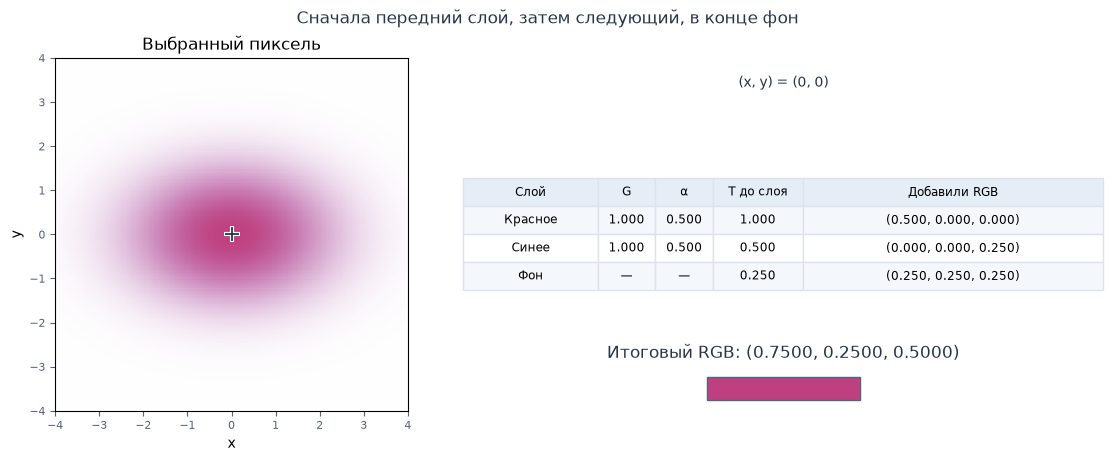

In [4]:
display(pixel_figure(language=LANG))

Теперь повторим расчёт в коде. Массив NumPy хранит три канала; умножение на число и сложение массивов выполняются покомпонентно, как мы только что делали вручную. `remaining` — наше $T$. Строки идут в том же порядке: красное, остаток, синее, остаток, фон.

In [5]:
red = np.array([1.0, 0.0, 0.0])
blue = np.array([0.0, 0.0, 1.0])
background = np.array([1.0, 1.0, 1.0])
alpha_red = 0.5
alpha_blue = 0.5

remaining = 1.0
from_red = remaining * alpha_red * red
remaining = remaining * (1 - alpha_red)
from_blue = remaining * alpha_blue * blue
remaining = remaining * (1 - alpha_blue)
from_background = remaining * background
pixel = from_red + from_blue + from_background

print("red       ", from_red)
print("blue      ", from_blue)
print("background", from_background)
print("pixel RGB ", pixel)

red        [0.5 0.  0. ]
blue       [0.   0.   0.25]
background [0.25 0.25 0.25]
pixel RGB  [0.75 0.25 0.5 ]


## 6. Почему перестановка меняет цвет

Поставим синее перед красным. Числа альф не поменялись, но долю `0.5` первым получит синий цвет, а красному достанется `0.25`:

$$
\begin{aligned}
C&=0.5(0,0,1)+0.25(1,0,0)+0.25(1,1,1)\\
&=(0,0,0.5)+(0.25,0,0)+(0.25,0.25,0.25)\\
&=(0.5,0.25,0.75).
\end{aligned}
$$

Теперь красного меньше, синего больше. Фон в обоих случаях получил `0.25`, потому что произведение оставшихся долей одинаково: $0.5\cdot0.5=0.25$.

Для двух произвольных пятен вся цепочка записывается так:

$$
C=\alpha_1 c_1+(1-\alpha_1)\alpha_2 c_2+(1-\alpha_1)(1-\alpha_2)B.
$$

Индексы 1 и 2 обозначают места в списке: первое пятно перед вторым. Первый член — вклад переднего пятна. Второй — вклад заднего с учётом того, что пропустило переднее. Последний — фон, прошедший через оба слоя. Это уже знакомые три шага, собранные в одну строку.

Обычное среднее красного и синего дало бы $(0.5,0,0.5)$. Оно не учитывает ни порядок, ни белый фон. Поэтому усреднение двух RGB не заменяет этот расчёт.

Иногда перестановка действительно ничего не меняет: например, если цвета пятен одинаковые или одно из них имеет нулевую альфу в рассматриваемом пикселе. Но в общем случае порядок важен.

## 7. Отойдём от центра и пройдём весь путь ещё раз

В центре было удобно: пространственный вес равнялся 1. Теперь выберем пиксель $(1.5,0)$. Центры обоих пятен по-прежнему $(0,0)$, масштабы $(1.5,1)$, поворота нет.

Сначала посчитаем гауссиану по уроку 3:

$$
\begin{aligned}
u&=(1.5-0)/1.5=1,\\
v&=(0-0)/1=0,\\
q&=1^2+0^2=1+0=1,\\
G&=\exp(-q/2)=\exp(-0.5)\approx0.606531.
\end{aligned}
$$

Буквы $u,v$ — смещения в единицах масштабов вдоль двух осей. $q$ — сумма их квадратов. Оба пятна имеют одинаковую форму и центр, поэтому оба дают этот вес.

У каждого непрозрачность `0.5`, значит:

$$
\alpha=0.5\exp(-0.5)\approx0.5\cdot0.60653066\approx0.303265.
$$

Дальше снова идём от красного к синему:

| Шаг | Доля | Вклад RGB |
|---|---|---|
| Красное | $1\cdot0.303265\approx0.303265$ | $(0.303265,0,0)$ |
| Осталось после красного | $1-0.303265\approx0.696735$ | Пока ничего не добавляем |
| Синее | $0.696735\cdot0.303265\approx0.211295$ | $(0,0,0.211295)$ |
| Осталось после синего | $0.696735(1-0.303265)\approx0.485439$ | Эта доля пойдёт фону |
| Белый фон | $0.485439$ | $(0.485439,0.485439,0.485439)$ |

Складываем каналы:

$$
\begin{aligned}
R&\approx0.303265+0.485439\approx0.788705,\\
G_{\text{канал}}&\approx0+0.485439=0.485439,\\
B_{\text{канал}}&\approx0.211295+0.485439\approx0.696735.
\end{aligned}
$$

Последние цифры считаем из неокруглённых значений; в тексте показано шесть знаков после точки. Получилось примерно `(0.788705, 0.485439, 0.696735)`. По сравнению с центром вклад белого фона вырос с `0.25` до `0.485439`: к краю оба пятна ослабли.

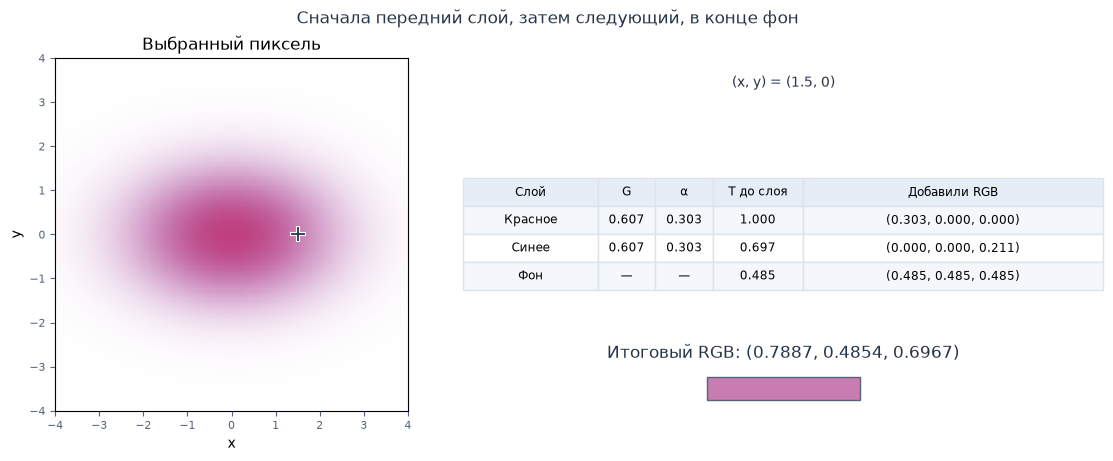

In [6]:
display(pixel_figure(x=1.5, y=0, language=LANG))

## 8. Тот же расчёт для любого числа пятен

Для третьего, десятого или двадцатого пятна нового правила не понадобится. В каждом пикселе повторяем два действия:

$$
\begin{aligned}
C_{\text{новое}}&=C_{\text{старое}}+T_{\text{старое}}\,\alpha_i c_i,\\
T_{\text{новое}}&=T_{\text{старое}}(1-\alpha_i).
\end{aligned}
$$

Индекс $i$ — номер текущего пятна. $\alpha_i$ — его альфа **в этом пикселе**, $c_i$ — его RGB. Сначала из старого остатка считаем цветовой вклад и прибавляем его к накопленному. Только потом обновляем остаток для следующего пятна. Если сначала уменьшить $T$, текущее пятно будет ошибочно ослаблять и само себя.

До первого пятна $C=(0,0,0)$ и $T=1$. После последнего добавляем $TB$. Именно этот последний шаг делает пустую сцену белой на белом фоне: пятен нет, $T$ осталось 1, итог $1\cdot B=B$.

Посмотрим, почему вклады не раздувают цвет бесконечно. Для двух пятен суммы долей равны:

$$
\begin{aligned}
&\alpha_1+(1-\alpha_1)\alpha_2+(1-\alpha_1)(1-\alpha_2)\\
&=\alpha_1+(1-\alpha_1)\bigl[\alpha_2+(1-\alpha_2)\bigr]\\
&=\alpha_1+(1-\alpha_1)\cdot1=1.
\end{aligned}
$$

Во второй строке вынесли общий множитель $1-\alpha_1$ из двух последних слагаемых. В скобках осталось $\alpha_2+1-\alpha_2=1$. Затем переднее пятно и весь остаток вместе снова дали 1. Каждый новый слой так же делит только оставшуюся часть.

Поэтому при альфах и каналах от 0 до 1 итоговые каналы тоже остаются в этом диапазоне. В нашем примере доли особенно простые: $0.5+0.25+0.25=1$. Это взвешенное смешивание; веса зависят от альф и порядка, а не обязаны быть равными.

В следующей функции форма гауссианы уже посчитана: на вход приходят готовые альфы для **одного** пикселя и цвета в порядке «спереди назад». Каждая пара в `alpha_colors` содержит одну альфу и одну RGB-тройку. В цикле повторяем формулу из двух строк. После цикла добавляем фон.

Цвета здесь хранятся без заранее включённой альфы. Поэтому умножаем на неё ровно один раз. Если заранее умножить цвет на альфу, а потом подать его в эту функцию как обычный цвет, вклад получится слишком слабым.

In [7]:
def blend_one_pixel(alpha_colors, background):
    color = np.zeros(3)
    remaining = 1.0
    for alpha, rgb in alpha_colors:
        color = color + remaining * alpha * np.asarray(rgb)
        remaining = remaining * (1 - alpha)
    return color + remaining * np.asarray(background)

front_red = [(0.5, (1, 0, 0)), (0.5, (0, 0, 1))]
front_blue = list(reversed(front_red))
print("Red in front: ", blend_one_pixel(front_red, (1, 1, 1)))
print("Blue in front:", blend_one_pixel(front_blue, (1, 1, 1)))

Red in front:  [0.75 0.25 0.5 ]
Blue in front: [0.5  0.25 0.75]


## 9. Что происходит на краях допустимых значений

**Непрозрачность ноль.** Тогда $\alpha=0\cdot G=0$ во всех пикселях. Цветовой вклад равен нулю, а остаток не меняется: $T(1-0)=T$. Пятно можно пропустить при смешивании, но его параметры всё ещё могут храниться в списке.

**Непрозрачность один.** В центре $G=1$, значит $\alpha=1$. Остаток становится $T(1-1)=0$: всё за этой точкой полностью скрыто. Но вдали от центра $G<1$, поэтому $\alpha=G<1$ и фон снова участвует. Настройка `1` не превращает всё пятно в непрозрачный диск.

**Два пятна с непрозрачностью 0.5.** Они не становятся полностью непрозрачными при наложении. В общем центре остаток $T=0.5\cdot0.5=0.25$. Значит, сами пятна заняли долю $1-T=1-0.25=0.75$. Просто сложить `0.5 + 0.5` здесь нельзя.

**Пустой список.** Остаётся только фон. Так работает пример «Чистый холст».

**Числа вне диапазона.** Для RGB и непрозрачности используем от 0 до 1 включительно. Отрицательная альфа давала бы отрицательный вклад, альфа больше 1 — отрицательный остаток. Это уже не наша модель. Масштабы пятна по-прежнему положительны, как в уроках 3–4.

Хвосты математической гауссианы не заканчиваются на пунктире. Редактор рисует только квадрат от −4 до 4 по обеим координатам; за его краями функция продолжается. Очень маленькие числа на компьютере могут потеряться из-за точности хранения, как мы обсуждали в уроке 2.

## 10. Соберём свою картинку

Вернись к редактору в начале урока. В поле **«Пример»** выбери **«Цветок»**, затем нажми **«Загрузить пример»**. Получится картинка из десяти гауссиан: середина, шесть лепестков, два листа и стебель. Ниже сохранён её исходный вид.

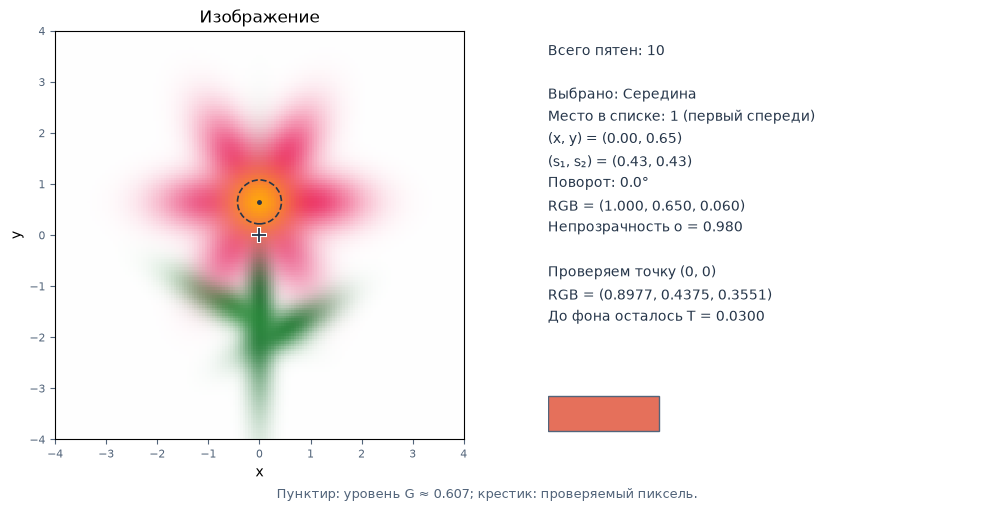

In [8]:
flower_layers, flower_background = preset_scene("flower", language=LANG)
display(editor_figure(flower_layers, flower_background, language=LANG))

Параметры одной гауссианы теперь можно связать с конкретной частью рисунка:

| Что меняем | Что наблюдаем |
|---|---|
| Центр `x`, `y` | Пятно переезжает |
| Масштабы `s₁`, `s₂` | Пятно растягивается вдоль собственных осей |
| Поворот | Направления этих осей поворачиваются вместе с пятном |
| Цвет | Меняются три RGB-канала самого пятна |
| Непрозрачность | Меняется сила вклада по всей форме |
| Место в списке | Меняется то, какие пятна ослабляют его вклад |
| Цвет фона | Меняется вклад, который остаётся после всех пятен |

Сначала сделай один лепесток длиннее и поверни его. Затем отправь середину цветка назад, под лепестки. Сравни результат и верни её вперёд. И здесь положение в списке иногда влияет сильнее, чем изменение цвета.

Кнопка **«Добавить пятно»** ставит новый элемент впереди списка. **«Удалить пятно»** убирает выбранный элемент. Кнопки перемещения меняют его место на одну позицию. Чтобы начать свою картинку, загрузи **«Чистый холст»**. **«Сбросить всё»** возвращает исходные красное и синее пятна, белый фон и крестик в центре.

Для проверки пикселя используется сетка `161 × 161`. Между −4 и 4 помещаются 160 промежутков: $(4-(-4))/160=8/160=0.05$. Поэтому один шаг ползунка пикселя равен `0.05` и соответствует соседнему центру пикселя. Меняя этот ползунок, мы только измеряем картинку, а не двигаем пятна.

В редакторе можно держать до 24 пятен. Центры ограничены диапазоном от −4 до 4, масштабы — от `0.2` до `3`, угол — от −180° до 180°. Это удобные границы панели управления, а не новые ограничения формулы гауссианы.

## 11. Сохраним сцену и загрузим обратно

Нажми **«Выгрузить JSON»**. В текстовом поле появятся параметры сцены, а над ним — ссылка для скачивания `gaussian-scene.json`. Можно скачать файл или просто скопировать текст.

JSON — текстовый способ записать данные. В нашем файле есть цвет фона и список пятен. У каждого пятна сохраняются имя, центр, два масштаба, угол, RGB и непрозрачность. Порядок элементов тоже сохраняется: первый остаётся передним. Это параметры рисунка, а не готовая картинка из пикселей.

Чтобы проверить сохранение:

1. Выгрузи сцену и сохрани JSON вне редактора.
2. Нажми «Сбросить всё» — картинка изменится.
3. Вставь сохранённый JSON в поле и нажми **«Загрузить JSON»**. Если скачивал файл, открой его как текст и скопируй содержимое.
4. Проверь несколько параметров и RGB под крестиком. При тех же координатах проверки результат должен совпасть.

Координаты крестика и пунктир — инструменты просмотра; в файл сцены они не входят. Поэтому для сравнения пикселя выставь то же положение крестика. Некорректный JSON или параметры вне диапазонов редактора не заменяют текущую сцену: появится сообщение, что нужно поправить.

Следующая ячейка делает такую же проверку через код. Она берёт **текущее** состояние редактора, сохраняет его в строку, читает обратно и сравнивает пиксель `(0, 0)`. Сцену на диске она не создаёт. После ручных изменений редактора ячейку можно запустить ещё раз.

In [9]:
saved_scene = editor.course_export()
restored_layers, restored_background = load_scene_json(saved_scene)
before = composite_at(0, 0, editor.course_state["layers"], editor.course_state["background"])["color"]
after = composite_at(0, 0, restored_layers, restored_background)["color"]
print("Spots:", len(restored_layers))
print("Before:", before)
print("After: ", after)
print("Same pixel:", np.allclose(before, after))

Spots: 2
Before: [0.75 0.25 0.5 ]
After:  [0.75 0.25 0.5 ]
Same pixel: True


## 12. Попробуй предсказать результат

### Задание 1. Красное выключили

Верни два пятна в общий центр. У красного спереди поставь непрозрачность `0`, у синего оставь `0.5`, фон белый. Какой RGB получится в центре?

<details>
<summary>Разбор</summary>

Красное имеет альфу 0, значит ничего не добавляет и оставляет $T=1$. Синее добавляет $1\cdot0.5(0,0,1)=(0,0,0.5)$. Остаток $T=1(1-0.5)=0.5$. Белый фон даёт $(0.5,0.5,0.5)$. Итог $(0.5,0.5,1)$. Перестановка с полностью выключенным красным ничего не изменит.

</details>

### Задание 2. Красное закрывает центр

Теперь у красного спереди поставь непрозрачность `1`. Что получится в центре? А обязано ли синее исчезнуть во всей картинке?

<details>
<summary>Разбор</summary>

В центре красного $G=1$, поэтому $\alpha=1\cdot1=1$. Вклад $(1,0,0)$, остаток $T=1(1-1)=0$. Синему и фону здесь ничего не достаётся: итог чисто красный. В стороне от центра $G<1$ и альфа меньше 1. Там заднее пятно и фон могут остаться видны.

</details>

### Задание 3. Чёрный фон

Верни непрозрачности обоих пятен `0.5` и красное вперёд. Замени белый фон чёрным. Посчитай RGB в центре.

<details>
<summary>Разбор</summary>

Красное даёт $(0.5,0,0)$, синее — $(0,0,0.25)$. Остаток `0.25` сохранился, но его умножаем на чёрный: $0.25(0,0,0)=(0,0,0)$. Итог $(0.5,0,0.25)$. Изменение фона не меняло ни веса гауссиан, ни альфы, ни доли переднего и заднего пятна.

</details>

### Задание 4. Почему порядок иногда незаметен?

Сделай оба пятна красными с непрозрачностью `0.5`. Будет ли меняться центр при перестановке? Фон белый.

<details>
<summary>Разбор</summary>

В обоих порядках один красный получает долю `0.5`, второй — `0.25`. Их общий вклад $0.75(1,0,0)=(0.75,0,0)$. Фон даёт $(0.25,0.25,0.25)$. Итог $(1,0.25,0.25)$. Важна не только смена долей, но и то, каким цветам они принадлежат. Здесь цвета совпали.

</details>

### Задание 5. Почти прозрачное пятно далеко от центра

У пятна непрозрачность `0.8`, а вес в проверяемой точке `0.25`. До него осталось $T=0.5$. Найди локальную альфу, долю этого пятна в пикселе и новый остаток.

<details>
<summary>Разбор</summary>

Сначала $\alpha=oG=0.8\cdot0.25=0.2$. Доля пятна в итоговом цвете $T\alpha=0.5\cdot0.2=0.1$. Новый остаток $T(1-\alpha)=0.5(1-0.2)=0.5\cdot0.8=0.4$. Пятно забрало `0.1` из прежнего остатка `0.5`, оставив `0.4`. Его RGB нужно умножить именно на `0.1`, а не на `0.8` или `0.2`.

</details>

## 13. Небольшая работа в конце блока

Загрузи чистый холст и собери узнаваемую картинку из **6–12 гауссиан**: цветок, рыбку, светящийся маяк или свой простой силуэт. Попробуй сделать её сам, не загружая готовый цветок.

Проверь свою сцену на четырёх опытах:

1. Хотя бы одно пятно вытянуто и повёрнуто. Объясни, какая ось стала длиннее и куда она смотрит.
2. Два пятна разных цветов перекрываются. Сохрани оба варианта их порядка и найди пиксель, где результат различается.
3. Уменьши непрозрачность одного пятна, сохранив его форму. Объясни изменение через $o$, $G$, $\alpha$ и $T$.
4. Выбери пиксель в области перекрытия. Для двух передних вкладов выпиши вес, альфу, старый остаток, добавленный RGB и новый остаток. Сверь каждый шаг с таблицей редактора. Остальные слои и фон тоже входят в окончательную сумму.

Выгрузи JSON, сбрось редактор и восстанови сцену. Сохранённый файл и расчёт одного пикселя — хороший способ проверить, что картинка получилась управляемой, а не случайной.

Теперь у нас есть вся цепочка первого блока: положение и форма задают пространственный вес; непрозрачность превращает его в альфу; цвет и порядок слоёв определяют вклад в пиксель; оставшуюся часть закрывает фон. Можно менять каждое число и объяснять, что произошло с изображением.

В [блоке 2](../../README_ru.md#блок-2-как-гауссианы-учатся) возьмём готовое изображение как цель. Сначала научимся измерять, насколько наш рисунок от него отличается, а потом будем менять параметры автоматически.

Если хочется сопоставить расчёт с принятой терминологией, смотри раздел [Simple alpha compositing в спецификации W3C](https://www.w3.org/TR/compositing-1/#simplealphacompositing). Здесь мы разобрали частный случай с непрозрачным фоном и обычным наложением слоёв.